In [ ]:
from google.colab import files

uploaded = files.upload()

Saving simple_login_activity.csv to simple_login_activity.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load uploaded CSV
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Available columns:", df.columns.tolist())

# Support both Lab 2 and Lab 3 naming conventions
if 'download_mb' not in df.columns and 'data_transfer_mb' in df.columns:
    df = df.rename(columns={'data_transfer_mb': 'download_mb'})

features = [
    'failed_logins',
    'login_hour',
    'new_device',
    'download_mb'
]

# Check required columns
missing = [col for col in features if col not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        "Please upload the correct Lab 2 login-activity dataset."
    )

# Identify target column
target_candidates = ['label', 'target', 'activity', 'class']
target_col = next(
    (col for col in target_candidates if col in df.columns),
    None
)

if target_col is None:
    raise ValueError("No target column found. Expected label, target, activity or class.")

# Prepare data
X = df[features].copy()
y = df[target_col].copy()

# Convert text labels into binary values
if not pd.api.types.is_numeric_dtype(y):
    label_map = {
        'normal': 0,
        'suspicious': 1,
        'attack': 1
    }

    y = y.astype(str).str.strip().str.lower().map(label_map)

    if y.isna().any():
        raise ValueError("Unknown labels found. Expected Normal, Suspicious or Attack.")

# Convert to numeric
X = X.apply(pd.to_numeric, errors='coerce')

# Remove missing values
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Split the dataset
class_counts = y.value_counts()

stratify_option = y if class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=stratify_option
)

# Train Decision Tree
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDataset preparation completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nClass distribution:")
print(y.value_counts())

Dataset loaded successfully!
Dataset shape: (101, 6)
Available columns: ['record_id', 'failed_logins', 'login_hour', 'new_device', 'download_mb', 'label']

Dataset preparation completed!
Training records: 74
Testing records: 25

Class distribution:
label
0    74
1    25
Name: count, dtype: int64


In [ ]:
# Five sanitized sample records
samples = pd.DataFrame([
    {
        'account_id': 'ACC-1001',
        'ip_address': '192.168.10.24',
        'failed_logins': 0,
        'login_hour': 10,
        'new_device': 0,
        'download_mb': 40
    },
    {
        'account_id': 'ACC-1002',
        'ip_address': '10.0.4.18',
        'failed_logins': 7,
        'login_hour': 2,
        'new_device': 1,
        'download_mb': 150
    },
    {
        'account_id': 'ACC-1003',
        'ip_address': '172.16.8.90',
        'failed_logins': 1,
        'login_hour': 15,
        'new_device': 0,
        'download_mb': 720
    },
    {
        'account_id': 'ACC-1004',
        'ip_address': '192.168.20.11',
        'failed_logins': 4,
        'login_hour': 23,
        'new_device': 1,
        'download_mb': 400
    },
    {
        'account_id': 'ACC-1005',
        'ip_address': '10.1.1.9',
        'failed_logins': 2,
        'login_hour': 9,
        'new_device': 0,
        'download_mb': 80
    }
])

# Predict classes
predictions = model.predict(samples[features])

# Calculate confidence
confidence = model.predict_proba(
    samples[features]
).max(axis=1)

# Convert predictions into readable labels
samples['prediction'] = np.where(
    predictions == 1,
    'Suspicious',
    'Normal'
)

samples['confidence'] = confidence.round(3)

print("BASELINE PREDICTIONS")
display(samples)

BASELINE PREDICTIONS


,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,0.972
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.000
2,ACC-1003,172.16.8.90,1,15,0,720,Normal,1.000
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.000
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,0.739


In [ ]:
# Calculate feature importance
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
})

# Sort by importance
importance = importance.sort_values(
    by='importance',
    ascending=False
)

print("FEATURE IMPORTANCE TABLE")
display(importance)

FEATURE IMPORTANCE TABLE


,feature,importance
0,failed_logins,0.391554
3,download_mb,0.281985
1,login_hour,0.249961
2,new_device,0.076500


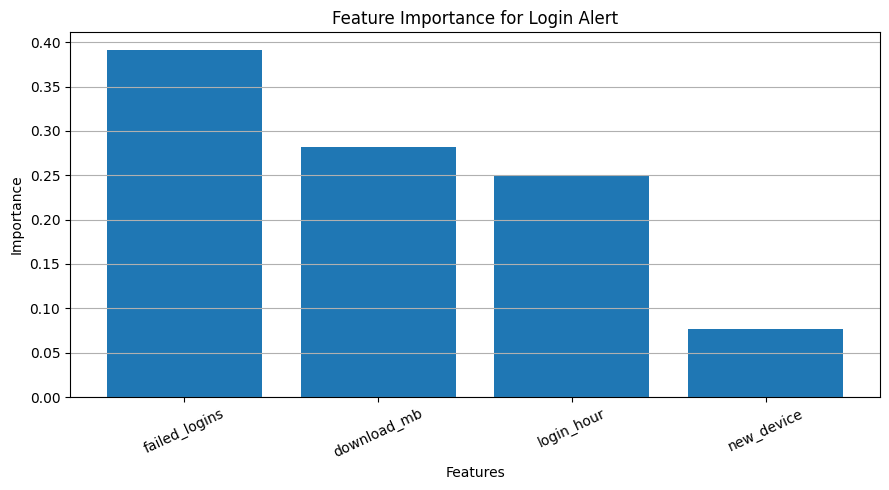

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    importance['feature'],
    importance['importance']
)

plt.title('Feature Importance for Login Alert')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=25)
plt.grid(axis='y')
plt.tight_layout()

plt.show()

In [ ]:
print("TOP THREE IMPORTANT FEATURES")
print("-" * 40)

for index, row in importance.head(3).iterrows():

    feature = row['feature']
    score = row['importance']

    explanations = {
        'failed_logins':
            'A high number of failed login attempts may indicate password guessing activity.',

        'login_hour':
            'Login activity at unusual hours may require additional verification.',

        'new_device':
            'Access from a new device may indicate unfamiliar account activity.',

        'download_mb':
            'A large data download may indicate unusual data access.'
    }

    print(f"\nFeature: {feature}")
    print(f"Importance: {score:.4f}")
    print(explanations[feature])

TOP THREE IMPORTANT FEATURES
----------------------------------------

Feature: failed_logins
Importance: 0.3916
A high number of failed login attempts may indicate password guessing activity.

Feature: download_mb
Importance: 0.2820
A large data download may indicate unusual data access.

Feature: login_hour
Importance: 0.2500
Login activity at unusual hours may require additional verification.


In [ ]:
# Select fifth baseline record
baseline = samples.iloc[[4]][features].copy()

# Make a copy
changed = baseline.copy()

# Change only failed_logins
changed['failed_logins'] = 8

# Original prediction
baseline_prediction = model.predict(baseline[features])[0]

baseline_confidence = model.predict_proba(
    baseline[features]
).max()

# Modified prediction
changed_prediction = model.predict(changed[features])[0]

changed_confidence = model.predict_proba(
    changed[features]
).max()

# Create comparison table
sensitivity_results = pd.DataFrame({
    'Version': ['Baseline', 'Modified'],
    'Failed Logins': [
        baseline['failed_logins'].iloc[0],
        changed['failed_logins'].iloc[0]
    ],
    'Prediction': [
        'Suspicious' if baseline_prediction == 1 else 'Normal',
        'Suspicious' if changed_prediction == 1 else 'Normal'
    ],
    'Confidence': [
        round(baseline_confidence, 3),
        round(changed_confidence, 3)
    ]
})

print("SENSITIVITY TEST RESULTS")
display(sensitivity_results)

SENSITIVITY TEST RESULTS


,Version,Failed Logins,Prediction,Confidence
0,Baseline,2,Normal,0.739
1,Modified,8,Suspicious,1.000


In [ ]:
# Function to mask IP address
def mask_ip(ip):

    parts = str(ip).split('.')

    if len(parts) == 4:
        return f'{parts[0]}.{parts[1]}.xxx.xxx'

    return '<MASKED_IP>'


# Function to mask account ID
def mask_account(account_id):

    text = str(account_id)

    return text[:4] + '***' + text[-2:]


# Apply masking
samples['masked_ip'] = samples['ip_address'].apply(mask_ip)

samples['masked_account'] = samples['account_id'].apply(
    mask_account
)

# Display only masked information
print("PRIVACY PROTECTED OUTPUT")

display(samples[[
    'masked_account',
    'masked_ip',
    'prediction',
    'confidence'
]])

PRIVACY PROTECTED OUTPUT


,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,0.972
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.000
2,ACC-***03,172.16.xxx.xxx,Normal,1.000
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.000
4,ACC-***05,10.1.xxx.xxx,Normal,0.739


In [ ]:
privacy_rules = [

    'Mask identifiers before displaying or exporting data.',

    'Use sanitized data in classroom notebooks.',

    'Restrict access to unmasked records to authorized personnel.',

    'Require human review before taking high-risk security actions.'

]

print("PRIVACY AND RESPONSIBLE-USE RULES")
print("-" * 45)

for number, rule in enumerate(privacy_rules, start=1):

    print(f"{number}. {rule}")

PRIVACY AND RESPONSIBLE-USE RULES
---------------------------------------------
1. Mask identifiers before displaying or exporting data.
2. Use sanitized data in classroom notebooks.
3. Restrict access to unmasked records to authorized personnel.
4. Require human review before taking high-risk security actions.


In [ ]:
# Function to identify reasons for suspicious activity

def numeric_reason(row):

    reasons = []

    if row['failed_logins'] >= 5:
        reasons.append('Many failed logins')

    if row['new_device'] == 1:
        reasons.append('New device detected')

    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('Unusual login time')

    if row['download_mb'] >= 500:
        reasons.append('Large data download')

    return ', '.join(reasons) if reasons else 'No strong warning'


# Function to generate security alerts

def make_alert(row):

    reason = numeric_reason(row)

    if row['prediction'] == 'Suspicious':

        severity = 'High'

        action = 'Verify, contain if required, and report.'

    elif row['confidence'] < 0.70:

        severity = 'Medium'

        action = 'Send for analyst review before action.'

    else:

        severity = 'Low'

        action = 'Continue normal monitoring.'

    human_review = (
        'Yes'
        if severity in ['High', 'Medium']
        else 'No'
    )

    return severity, reason, action, human_review


# Generate alerts for all five records

alerts = samples.apply(make_alert, axis=1)

# Add alert information to dataset

samples[[
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]] = pd.DataFrame(
    alerts.tolist(),
    index=samples.index
)

# Display final privacy-safe alert table

print("FINAL RESPONSIBLE AI SECURITY ALERTS")

display(samples[[
    'masked_account',
    'prediction',
    'confidence',
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]])

FINAL RESPONSIBLE AI SECURITY ALERTS


,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,0.972,Low,No strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.000,High,"Many failed logins, New device detected, Unusu...","Verify, contain if required, and report.",Yes
2,ACC-***03,Normal,1.000,Low,Large data download,Continue normal monitoring.,No
3,ACC-***04,Suspicious,1.000,High,"New device detected, Unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,0.739,Low,No strong warning,Continue normal monitoring.,No


In [ ]:
print("=" * 60)
print("AI SECURITY THREAT ALERT SUMMARY")
print("=" * 60)

print("\nTotal Records:", len(samples))

print("\nSeverity Distribution:")

print(samples['severity'].value_counts())

print("\nRecords Requiring Human Review:")

print(
    (samples['human_review'] == 'Yes').sum()
)

print("\nHigh Severity Alerts:")

print(
    (samples['severity'] == 'High').sum()
)

print("\nFinal Alert Table:")

display(samples[[
    'masked_account',
    'prediction',
    'confidence',
    'severity',
    'reason',
    'recommended_action',
    'human_review'
]])

print("\nSUMMARY GENERATED SUCCESSFULLY!")
print("=" * 60)

AI SECURITY THREAT ALERT SUMMARY

Total Records: 5

Severity Distribution:
severity
Low     3
High    2
Name: count, dtype: int64

Records Requiring Human Review:
2

High Severity Alerts:
2

Final Alert Table:


,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,0.972,Low,No strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.000,High,"Many failed logins, New device detected, Unusu...","Verify, contain if required, and report.",Yes
2,ACC-***03,Normal,1.000,Low,Large data download,Continue normal monitoring.,No
3,ACC-***04,Suspicious,1.000,High,"New device detected, Unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,0.739,Low,No strong warning,Continue normal monitoring.,No



SUMMARY GENERATED SUCCESSFULLY!
